In [1]:
# Import libraries
%load_ext autoreload
%autoreload 2

from IPython.display import display
import os
from tqdm import tqdm
import ast
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import matplotlib.markers as mmarkers
import scipy
from sklearn.linear_model import Ridge, Lasso

from compcats.localizer import localizer
from compcats.datasets.fmri import nsd
from compcats.utils import model_utils, misc_utils, responsecomparison_utils as rc_utils
from compcats.models import resnet50_openaiclip, alexnet_imagenet1kv1

import main_analysis as ma
import paths

# Matplotlib settings
import matplotlib as mpl
from matplotlib import rcParams
rcParams.update({'figure.autolayout': False})
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
# Font
font_path = '/home/alishd/.fonts/Avenir.ttc'
avenir_font = fm.FontProperties(fname=font_path)
mpl.rcParams['font.family'] = avenir_font.get_name()
ttc = fm.get_font(font_path)
print("Font name from TTC:", ttc.family_name)
print("Style:", ttc.style_name)

RESULTS_DIR = 'results'
MODELS_DIR = 'models'

NSD_DIR = paths.NSD_DIR
GRILLSPECTOR_LOCALIZER_DIR = paths.GRILLSPECTOR_LOCALIZER_DIR

splithalf_csv = pd.read_csv(f'{ma.SUBJECTSUBJECT_CORRELATIONS_CSV_PATH}')

Font name from TTC: Avenir
Style: Book


# Dev

In [ ]:
# froi = 'FFA'
# tthreshold = 7
# subject = 1
# # Get s1 FFA data
# Y_train, _ = nsd.get_betas(
#     NSD_DIR, subject, froi, tthreshold, 485, True
# )
# Y_test, _ = nsd.get_betas(
#     NSD_DIR, subject, froi, tthreshold, 515, True
# )
# # Get model full layer activations
# model_r50c = resnet50_openaiclip.get_model()
# layer_r50c = ma.get_froi_models_layers(froi, froi)[model_r50c.name]
# X_train_r50c = model_utils.get_dataset_activations(
#     MODELS_DIR, NSD_DIR, model_r50c, layer_r50c,
#     'nsd', subset=485
# )
# X_test_r50c = model_utils.get_dataset_activations(
#     MODELS_DIR, NSD_DIR, model_r50c, layer_r50c,
#     'nsd', subset=515
# )
# model_alximg = alexnet_imagenet1kv1.get_model()
# layer_alximg = ma.get_froi_models_layers(froi, froi)[model_alximg.name]
# X_train_alximg = model_utils.get_dataset_activations(
#     MODELS_DIR, NSD_DIR, model_alximg, layer_alximg,
#     'nsd', subset=485
# )
# X_test_alximg = model_utils.get_dataset_activations(
#     MODELS_DIR, NSD_DIR, model_alximg, layer_alximg,
#     'nsd', subset=515
# )
# # Get model's FFA units
# froi_msdk_r50c = localizer.get_froi_mask(
#     GRILLSPECTOR_LOCALIZER_DIR, 'grillspector', MODELS_DIR,
#     model_r50c, layer_r50c, froi, tthreshold
# )
# froi_msdk_alximg = localizer.get_froi_mask(
#     GRILLSPECTOR_LOCALIZER_DIR, 'grillspector', MODELS_DIR,
#     model_alximg, layer_alximg, froi, tthreshold
# )

# # Convert tensors to numpy arrays and move to CPU
# X_train_r50c = X_train_r50c.cpu().numpy()
# X_test_r50c = X_test_r50c.cpu().numpy()
# X_train_alximg = X_train_alximg.cpu().numpy()
# X_test_alximg = X_test_alximg.cpu().numpy()

In [ ]:
# results_r50c = get_em_performances(
#     X_train_r50c, Y_train, X_test_r50c, Y_test,
#     'ridge', 0.1, froi_msdk_r50c, splithalf_csv
# )
# x1, x2 = get_em_performances(
#     X_train_alximg, Y_train, X_test_alximg, Y_test,
#     'ridge', 0.1, froi_msdk_alximg, splithalf_csv
# )

In [ ]:
# plt.bar(
#     ['allunits', 'froi0weights', 'random0weights'],
#     [results_r50c['allunits_normed_pearsonr'], results_r50c['froi0weights_normed_pearsonr'], 
#      np.mean(results_r50c['random0weights_normed_pearsonrs'])],
#     yerr=[0,
#           0,
#           scipy.stats.sem(results_r50c['random0weights_normed_pearsonrs'])]
# )
# plt.scatter(
#     [2-0.15]*len(results_r50c['random0weights_normed_pearsonrs']), 
#     results_r50c['random0weights_normed_pearsonrs'], color='red', label='fROI 0 weights',
#     s=2
# )
# plt.ylim(0.8, 1)
# plt.show()

# Analysis

In [2]:
# Util function

def get_em_performances(
        X_train, Y_train, X_test, Y_test, mapper, alpha, froi_mask, splithalf_csv,
        n_bootstrap = 10
):
    """
    Train an encoding model and return the performance.
    """
    results = {
        # Weights
        'allunits_weights_coef': None,
        'allunits_weights_intercept': None,
        # Splithalf correlations
        'splithalf_pearsonr': None,
        'splithalf_rdmr': None,
        # Baseline
        'allunits_raw_pearsonr': None,
        'allunits_raw_rdmr': None,
        'allunits_normed_pearsonr': None,
        'allunits_normed_rdmr': None,
        # Set fROI weights to zero
        'froi0weights_raw_pearsonr': None,
        'froi0weights_raw_rdmr': None,
        'froi0weights_normed_pearsonr': None,
        'froi0weights_normed_rdmr': None,
        # Randomly zero out weights except fROI
        'random0weights_raw_pearsonrs': [],
        'random0weights_raw_rdmrs': [],
        'random0weights_normed_pearsonrs': [],
        'random0weights_normed_rdmrs': [],
        # # Shuffle fROI features
        # 'froiperm_raw_pearsonr': None,
        # 'froiperm_raw_rdmr': None,
        # 'froiperm_normed_pearsonr': None,
        # 'froiperm_normed_rdmr': None,
        # # Randomly shuffle features except fROI
        # 'randomperm_raw_pearsonrs': [],
        # 'randomperm_raw_rdmrs': [],
        # 'randomperm_normed_pearsonrs': [],
        # 'randomperm_normed_rdmrs': [],
        # # Lesion fROI features and retrain the model
        # 'froiremove_raw_pearsonr': None,
        # 'froiremove_raw_rdmr': None,
        # 'froiremove_normed_pearsonr': None,
        # 'froiremove_normed_rdmr': None,
        # # Randomly lesion features except fROI and retrain the model
        # 'randomremove_raw_pearsonrs': [],
        # 'randomremove_raw_rdmrs': [],
        # 'randomremove_normed_pearsonrs': [],
        # 'randomremove_normed_rdmrs': [],
    }
    # Initialize the mapping model based on the mapper type
    if mapper == 'ridge':
        mapping_model = Ridge(alpha=alpha)
    elif mapper == 'l1positive':
        mapping_model = Lasso(alpha=alpha, positive=True)
    else:
        raise ValueError(f"Unknown mapper: {mapper}")
    
    # Get the split-half correlations for the subjects
    # Splithalf correlations
    splithalf_info = splithalf_csv[
        (splithalf_csv['fmri_froi'] == 'FFA') &
        (splithalf_csv['fmri_tthreshold'] == 7) &
        (splithalf_csv['fmri_dataset'] == 'nsd515') &
        (splithalf_csv['subject1'] == 1)
    ].iloc[0]
    splithalf_pearsonr = splithalf_info['subject1_splithalf_pearsonr'].item()
    splithalf_rdmr = splithalf_info['subject1_splithalf_rdmr'].item()

    # Train an encoding model on all the units
    x_train = X_train.reshape(X_train.shape[0], -1)
    y_train = Y_train
    assert y_train.ndim == 2, "Y_train should be 2D, sample x voxels"
    mapping_model.fit(x_train, y_train)
    # Check the encoding model performance
    x_test = X_test.reshape(X_test.shape[0], -1)
    y_pred = mapping_model.predict(x_test)
    y_test = Y_test
    # Convert to torch tensors and move to GPU for compatibility with rc_utils
    y_pred = torch.Tensor(y_pred).to('cuda' if torch.cuda.is_available() else 'cpu')
    y_test = torch.Tensor(y_test).to('cuda' if torch.cuda.is_available() else 'cpu')
    # Calculate Pearson correlation and RDM correlation
    allunits_raw_pearsonr = rc_utils.pearsonr(y_pred.mean(axis=-1), y_test.mean(axis=-1))
    allunits_raw_rdmr = rc_utils.rdmr(y_pred, y_test)
    # Normalize with split-half correlations
    allunits_normed_pearsonr = (allunits_raw_pearsonr / np.sqrt(splithalf_pearsonr)).item()
    allunits_normed_rdmr = (allunits_raw_rdmr / np.sqrt(splithalf_rdmr)).item()
    # Store the results
    results['allunits_weights_coef'] = mapping_model.coef_
    results['allunits_weights_intercept'] = mapping_model.intercept_
    results['splithalf_pearsonr'] = splithalf_pearsonr
    results['splithalf_rdmr'] = splithalf_rdmr
    results['allunits_raw_pearsonr'] = allunits_raw_pearsonr
    results['allunits_raw_rdmr'] = allunits_raw_rdmr
    results['allunits_normed_pearsonr'] = allunits_normed_pearsonr
    results['allunits_normed_rdmr'] = allunits_normed_rdmr

    # Set fROI weights to zero
    froi_mask_flat = froi_mask.reshape(-1)
    model_copy_coef = mapping_model.coef_.copy()
    model_copy_coef[:, froi_mask_flat] = 0
    # Make a new model with the modified weights
    model_copy = None
    if mapper == 'ridge':
        model_copy = Ridge(alpha=alpha)
    elif mapper == 'l1positive':
        model_copy = Lasso(alpha=alpha, positive=True)
    model_copy.coef_ = model_copy_coef
    model_copy.intercept_ = mapping_model.intercept_
    # Predict with the modified model
    y_pred_froiwt0 = model_copy.predict(x_test)
    # Calculate Pearson correlation and RDM correlation
    y_pred_froiwt0 = torch.Tensor(y_pred_froiwt0).to('cuda' if torch.cuda.is_available() else 'cpu')
    y_test = torch.Tensor(y_test).to('cuda' if torch.cuda.is_available() else 'cpu')
    froi0weights_raw_pearsonr = rc_utils.pearsonr(y_pred_froiwt0.mean(axis=-1), y_test.mean(axis=-1))
    froi0weights_raw_rdmr = rc_utils.rdmr(y_pred_froiwt0, y_test)
    # Normalize with split-half correlations
    froi0weights_normed_pearsonr = (froi0weights_raw_pearsonr / np.sqrt(splithalf_pearsonr)).item()
    froi0weights_normed_rdmr = (froi0weights_raw_rdmr / np.sqrt(splithalf_rdmr)).item()
    # Store the results
    results['froi0weights_raw_pearsonr'] = froi0weights_raw_pearsonr
    results['froi0weights_raw_rdmr'] = froi0weights_raw_rdmr
    results['froi0weights_normed_pearsonr'] = froi0weights_normed_pearsonr
    results['froi0weights_normed_rdmr'] = froi0weights_normed_rdmr

    # Control: Randomly zero out weights except fROI
    n_random = froi_mask_flat.sum().item()
    random_indices_log = []
    for _ in range(n_bootstrap):
        # Get indices where froi_mask_flat is False
        false_indices = torch.where(froi_mask_flat == False)[0]
        # Randomly select n_random indices from the false indices
        random_indices = torch.randperm(len(false_indices))[:n_random]
        random_indices = false_indices[random_indices]
        random_indices_log.append(random_indices)
        # Create a copy of the model and set the selected indices to zero
        model_copy_coef = mapping_model.coef_.copy()
        model_copy_coef[:, random_indices] = 0
        # Make a new model with the modified weights
        model_copy = None
        if mapper == 'ridge':
            model_copy = Ridge(alpha=alpha)
        elif mapper == 'l1positive':
            model_copy = Lasso(alpha=alpha, positive=True)
        model_copy.coef_ = model_copy_coef
        model_copy.intercept_ = mapping_model.intercept_
        # Predict with the modified model
        y_pred_randomwt0 = model_copy.predict(x_test)
        # Calculate Pearson correlation and RDM correlation
        y_pred_randomwt0 = torch.Tensor(y_pred_randomwt0).to('cuda' if torch.cuda.is_available() else 'cpu')
        y_test = torch.Tensor(y_test).to('cuda' if torch.cuda.is_available() else 'cpu')
        random0weights_raw_pearsonr = rc_utils.pearsonr(y_pred_randomwt0.mean(axis=-1), y_test.mean(axis=-1))
        random0weights_raw_rdmr = rc_utils.rdmr(y_pred_randomwt0, y_test)
        # Normalize with split-half correlations
        random0weights_normed_pearsonr = (random0weights_raw_pearsonr / np.sqrt(splithalf_pearsonr)).item()
        random0weights_normed_rdmr = (random0weights_raw_rdmr / np.sqrt(splithalf_rdmr)).item()
        # Store the results
        results['random0weights_raw_pearsonrs'].append(random0weights_raw_pearsonr)
        results['random0weights_raw_rdmrs'].append(random0weights_raw_rdmr)
        results['random0weights_normed_pearsonrs'].append(random0weights_normed_pearsonr)
        results['random0weights_normed_rdmrs'].append(random0weights_normed_rdmr)
    # Log the random indices for reproducibility
    results['random0weights_indices_log'] = np.array(random_indices_log)
    return results

# Train an encoding model on all the units except FFA
# Check the encoding model performance

In [3]:
frois = ['FFA', 'PPA', 'EBA']
tthreshold = 7
subjects = [1, 2, 5, 7]
model_localizer = 'grillspector'
model_localizer_dir = GRILLSPECTOR_LOCALIZER_DIR
mapper = 'ridge'
mapper_alpha = 0.1

all_models = ma.get_all_models()

Using cache found in /home/alishd/.cache/torch/hub/harvard-visionlab_open_ipcl_main


/home/alishd/.cache/torch/checkpoints/1a6IO4xhWy8cdyAuWv0BxSONz7lMcKbZE.pth.tar


/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Using cached ./models


No pretrained configuration specified for vit_base_patch16_224_in21k model. Using a default. Please add a config to the model pretrained_cfg registry or pass explicitly.
Using cache found in /home/alishd/.cache/torch/hub/facebookresearch_dinov2_main
/home/alishd/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:43: UserWarning: xFormers is available (SwiGLU)
  warnings.warn("xFormers is available (SwiGLU)")
/home/alishd/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:27: UserWarning: xFormers is available (Attention)
  warnings.warn("xFormers is available (Attention)")
/home/alishd/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:33: UserWarning: xFormers is available (Block)
  warnings.warn("xFormers is available (Block)")
Using cache found in /home/alishd/.cache/torch/hub/facebookresearch_dinov2_main


In [9]:
results_dir = f'{RESULTS_DIR}/exploration/lesioning'
os.makedirs(results_dir, exist_ok=True)
csv_path = os.path.join(results_dir, 'lesioning_results.csv')
if os.path.exists(csv_path):
    results_csv = pd.read_csv(csv_path)
    results_csv_list = results_csv.to_dict('records')
else:
    results_csv_list = []

total_iters = len(frois) * len(subjects) * len(all_models)
with tqdm(total=total_iters) as pbar:
    for froi in frois:
        X_train_all_models = {}
        X_test_all_models = {}
        for model_name, model in all_models.items():
            layer = ma.get_froi_models_layers(froi, froi)[model_name]
            # Get model full layer activations
            X_train_all_models[model_name] = model_utils.get_dataset_activations(
                MODELS_DIR, NSD_DIR, model, layer,
                'nsd', subset=485
            )
            X_test_all_models[model_name] = model_utils.get_dataset_activations(
                MODELS_DIR, NSD_DIR, model, layer,
                'nsd', subset=515
            )
        for subject in subjects:
            # Get fROI data
            Y_train, _ = nsd.get_betas(
                NSD_DIR, subject, froi, tthreshold, 485, True
            )
            Y_test, _ = nsd.get_betas(
                NSD_DIR, subject, froi, tthreshold, 515, True
            )
            for model_name, model in all_models.items():
                layer = ma.get_froi_models_layers(froi, froi)[model_name]
                row_params = {
                    'model': model_name,
                    'layer': layer,
                    'model_froi': froi,
                    'fmri_froi': froi,
                    'model_tthreshold': tthreshold,
                    'fmri_tthreshold': tthreshold,
                    'model_localizer': model_localizer,
                    'subject': subject,
                    'mapper': mapper,
                    'mapper_alpha': mapper_alpha,
                }
                if misc_utils.check_row_present(row_params, results_csv_list):
                    pbar.update(1)
                    continue
                results_dict = row_params.copy()
                # Get model full layer activations
                # Get model X_train & X_test Convert tensors to numpy arrays and move to CPU
                X_train = X_train_all_models[model_name].cpu().numpy()
                X_test = X_test_all_models[model_name].cpu().numpy()
                # Get model's fROI units
                froi_mask = localizer.get_froi_mask(
                    model_localizer_dir, model_localizer, MODELS_DIR,
                    model, layer, froi, tthreshold
                )
                # Get encoding model performances
                model_results = get_em_performances(
                    X_train, Y_train, X_test, Y_test,
                    mapper, mapper_alpha, froi_mask, splithalf_csv
                )
                # Store results in a dataframe
                results_dict.update({
                    'allunits_raw_pearsonr': model_results['allunits_raw_pearsonr'],
                    'allunits_raw_rdmr': model_results['allunits_raw_rdmr'],
                    'allunits_normed_pearsonr': model_results['allunits_normed_pearsonr'],
                    'allunits_normed_rdmr': model_results['allunits_normed_rdmr'],
                    'froi0weights_raw_pearsonr': model_results['froi0weights_raw_pearsonr'],
                    'froi0weights_raw_rdmr': model_results['froi0weights_raw_rdmr'],
                    'froi0weights_normed_pearsonr': model_results['froi0weights_normed_pearsonr'],
                    'froi0weights_normed_rdmr': model_results['froi0weights_normed_rdmr'],
                    'random0weights_raw_pearsonrs': model_results['random0weights_raw_pearsonrs'],
                    'random0weights_raw_rdmrs': model_results['random0weights_raw_rdmrs'],
                    'random0weights_normed_pearsonrs': model_results['random0weights_normed_pearsonrs'],
                    'random0weights_normed_rdmrs': model_results['random0weights_normed_rdmrs'],
                })
                results_csv_list.append(results_dict)
                # Save intermediate results to CSV
                results_df = pd.DataFrame(results_csv_list)
                results_df.to_csv(csv_path, index=False)
                pbar.update(1)

  1%|          | 5/420 [00:25<36:53,  5.33s/it]/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:254: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
  1%|▏         | 6/420 [00:49<1:08:02,  9.86s/it]/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:254: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
  2%|▏         | 7/420 [01:15<1:34:01, 13.66s/it]/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:254: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
  2%|▏         | 7/420 [01:57<1:55:34, 16.79s/it]


KeyboardInterrupt: 

# Plot

In [2]:
results_dir = f'{RESULTS_DIR}/exploration/lesioning'
os.makedirs(results_dir, exist_ok=True)
results_csv_path = os.path.join(results_dir, 'lesioning_results.csv')
results_df = pd.read_csv(results_csv_path)

# Take the median for random0weights_raw_pearsonrs, random0weights_raw_rdmrs, random0weights_normed_pearsonrs, and random0weights_normed_rdmrs individually
results_df['random0weights_raw_pearsonr'] = results_df['random0weights_raw_pearsonrs'].apply(ast.literal_eval).apply(np.median)
results_df['random0weights_raw_rdmr'] = results_df['random0weights_raw_rdmrs'].apply(ast.literal_eval).apply(np.median)
results_df['random0weights_normed_pearsonr'] = results_df['random0weights_normed_pearsonrs'].apply(ast.literal_eval).apply(np.median)
results_df['random0weights_normed_rdmr'] = results_df['random0weights_normed_rdmrs'].apply(ast.literal_eval).apply(np.median)

## All units vs. froi vs. random

froi: FFA, metric: normed_pearsonr: All units normality p-value: 9.28e-04, fROI lesion normality p-value: 1.48e-04, Random lesion normality p-value: 1.06e-03
froi: FFA, metric: normed_rdmr: All units normality p-value: 8.91e-03, fROI lesion normality p-value: 4.53e-03, Random lesion normality p-value: 7.97e-03
froi: PPA, metric: normed_pearsonr: All units normality p-value: 2.84e-02, fROI lesion normality p-value: 6.18e-03, Random lesion normality p-value: 1.53e-02
froi: PPA, metric: normed_rdmr: All units normality p-value: 2.07e-01, fROI lesion normality p-value: 9.08e-02, Random lesion normality p-value: 1.56e-01
froi: EBA, metric: normed_pearsonr: All units normality p-value: 1.72e-01, fROI lesion normality p-value: 9.59e-02, Random lesion normality p-value: 1.59e-01
froi: EBA, metric: normed_rdmr: All units normality p-value: 9.20e-02, fROI lesion normality p-value: 5.49e-02, Random lesion normality p-value: 1.03e-01


,froi,metric,allunits_normality_pvalue,froilesion_normality_pvalue,randomlesion_normality_pvalue,allunits_froi_ttest_tvalue,allunits_froi_ttest_pvalue,random_froi_ttest_tvalue,random_froi_ttest_pvalue,allunits_froi_mw_uvalue,allunits_froi_mw_pvalue,random_froi_mw_uvalue,random_froi_mw_pvalue
0,FFA,normed_pearsonr,0.000928,0.000148,0.001055,1.338339,0.185436,-1.326843,0.189187,0.0,5.820766e-11,0.0,5.820766e-11
1,FFA,normed_rdmr,0.008910,0.004535,0.007965,1.527563,0.131323,-1.519834,0.133248,0.0,5.820766e-11,0.0,5.820766e-11
2,PPA,normed_pearsonr,0.028363,0.006184,0.015255,0.515255,0.608068,-0.480887,0.632154,0.0,5.820766e-11,0.0,5.820766e-11
3,PPA,normed_rdmr,0.207176,0.090836,0.156491,0.467557,0.641604,-0.441181,0.660486,0.0,5.820766e-11,0.0,5.820766e-11
4,EBA,normed_pearsonr,0.171716,0.095934,0.158721,0.787257,0.433965,-0.713991,0.477743,4.0,4.074536e-10,20.0,2.159504e-08
5,EBA,normed_rdmr,0.092036,0.054913,0.102641,0.667624,0.506668,-0.637957,0.525673,9.0,1.920853e-09,16.0,9.837095e-09


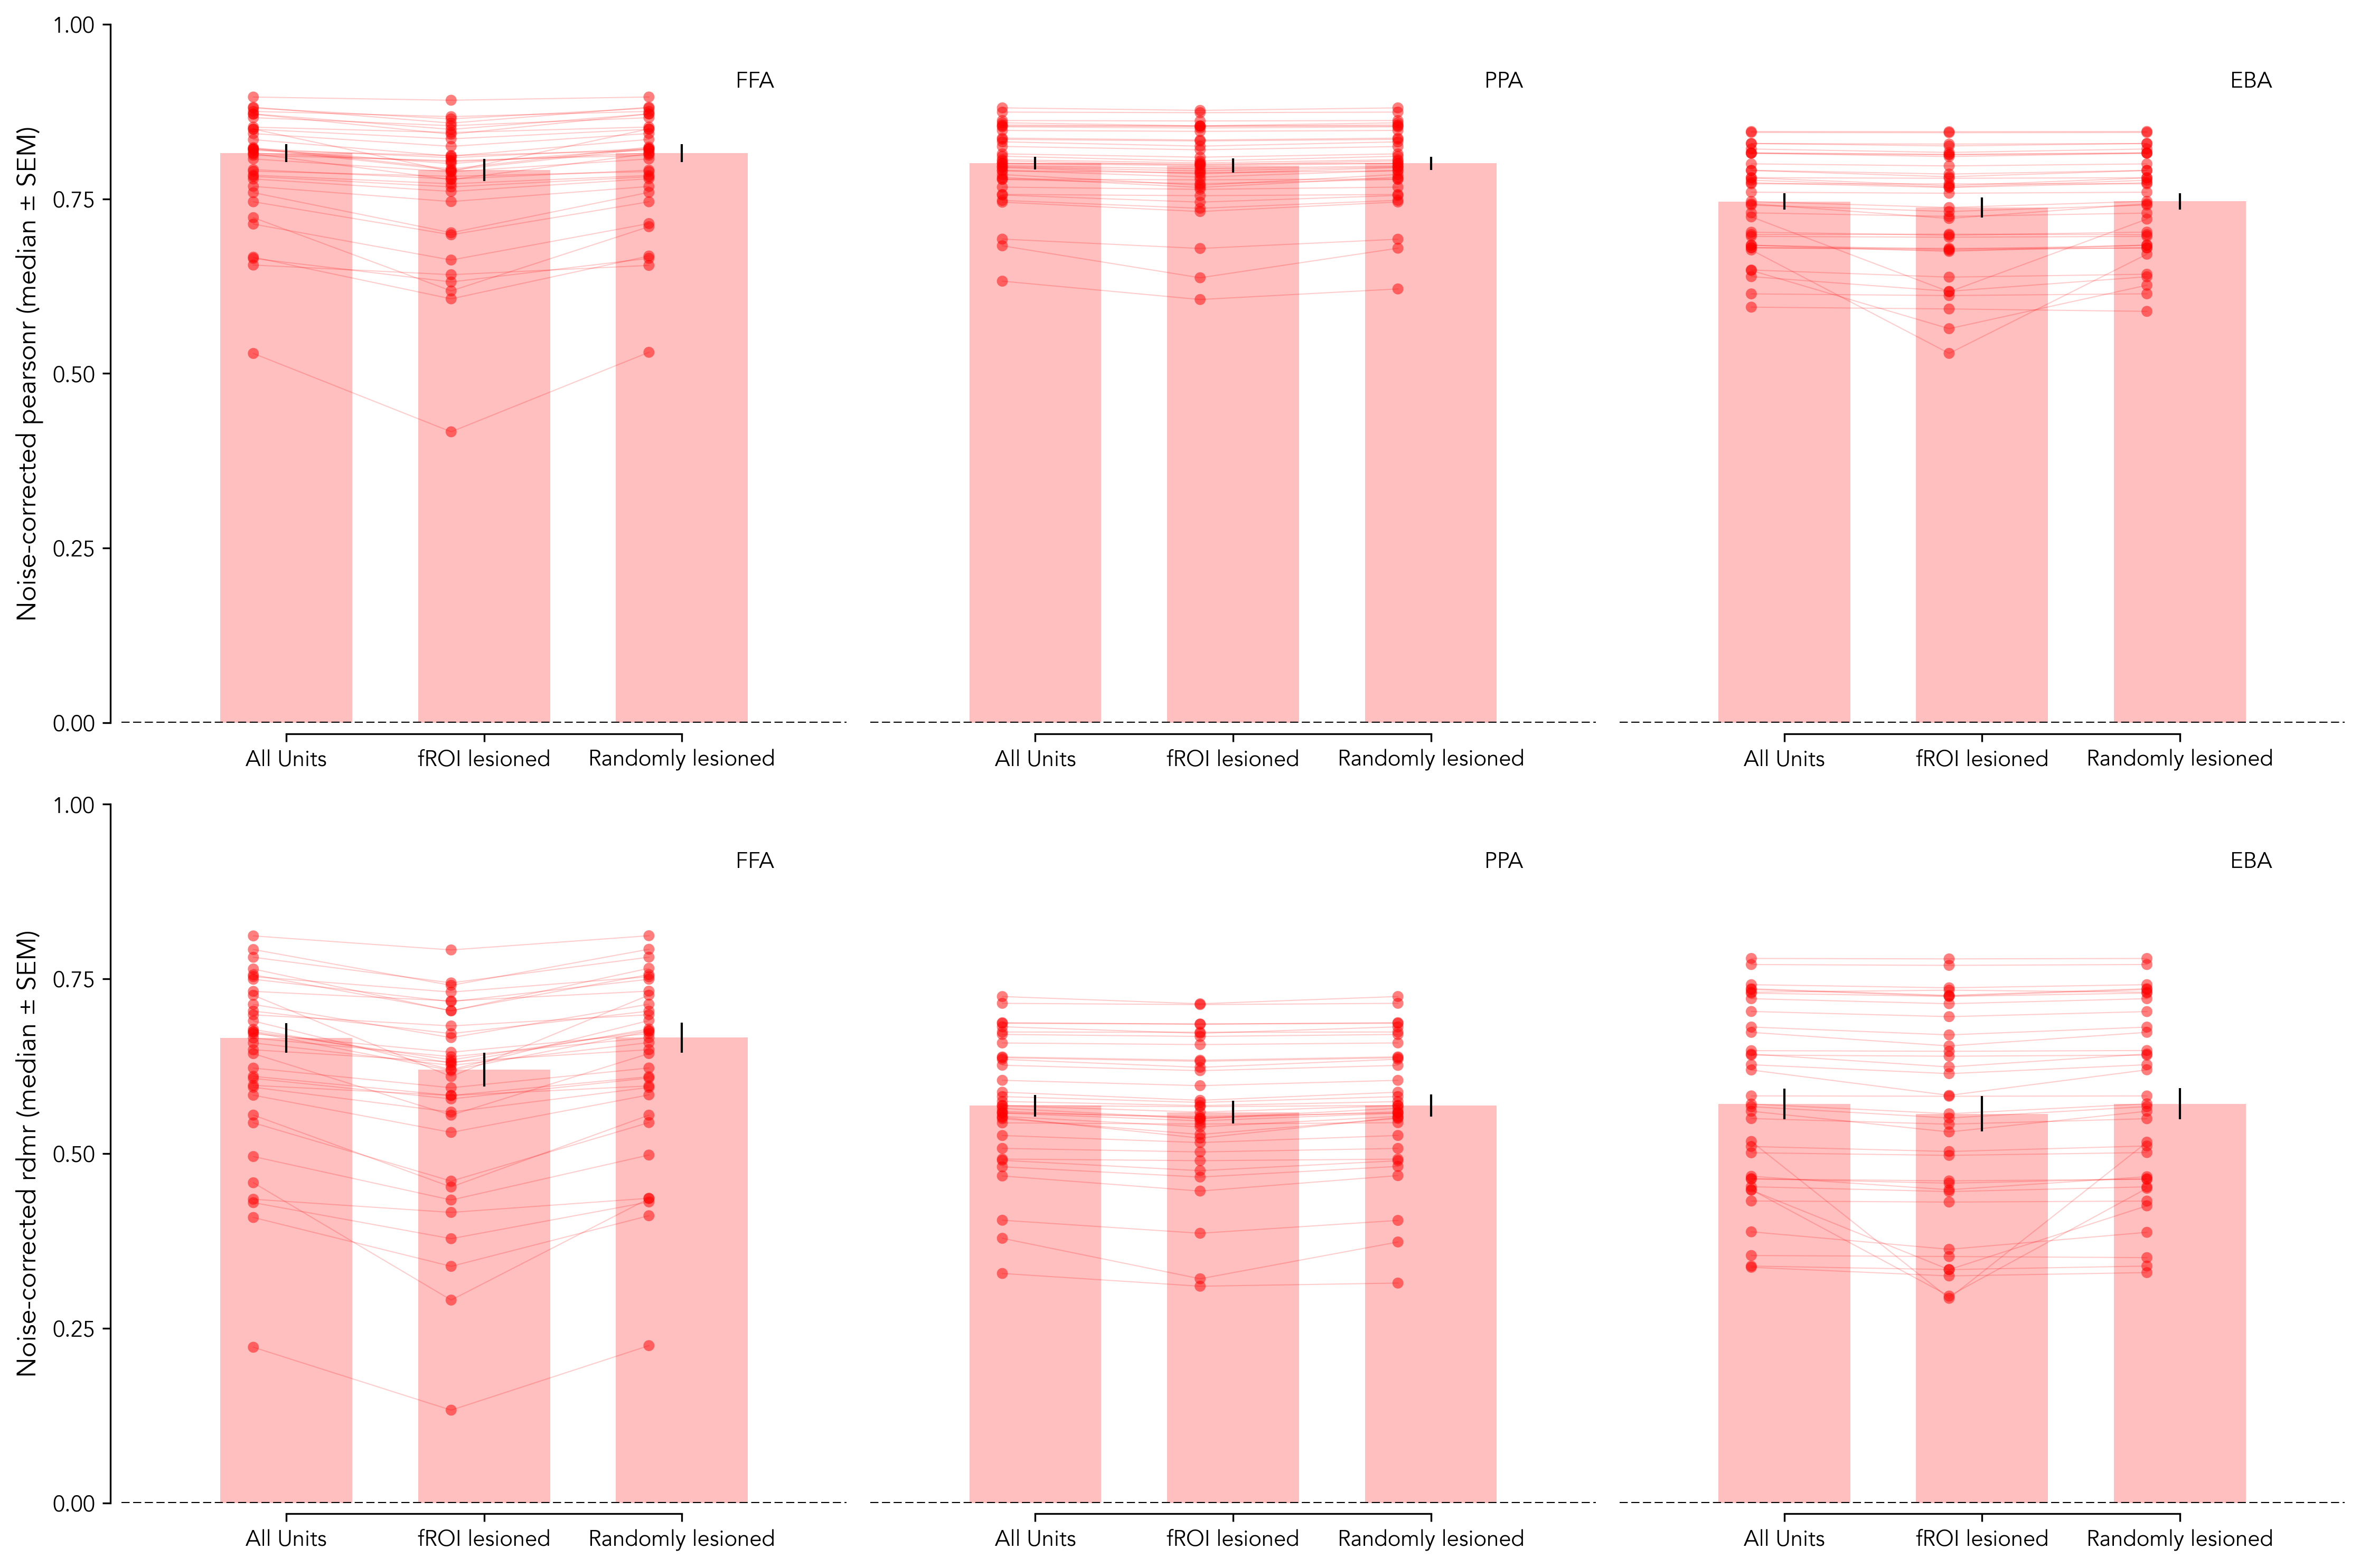

In [ ]:
savefig = False

plot_dir = f'{results_dir}/plots'

frois = ['FFA', 'PPA', 'EBA']
metrics = ['normed_pearsonr', 'normed_rdmr']

# Take median across subjects for each model, model_froi, fmri_froi
results_df_froi_sbjmedian = results_df.groupby(
    ['model', 'model_froi', 'fmri_froi']
).agg({
    'allunits_normed_pearsonr': 'median',
    'allunits_normed_rdmr': 'median',
    'froi0weights_normed_pearsonr': 'median',
    'froi0weights_normed_rdmr': 'median',
	'random0weights_normed_pearsonr': 'median',
    'random0weights_normed_rdmr': 'median',
}).reset_index()

fig, axs = plt.subplots(len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300)

x_offset = 0.05
alpha = 0.5
markersize = 25
x = [0, 0.3, 0.6]

stats_df = []
for fidx, froi in enumerate(frois):
    results_df_froi = results_df_froi_sbjmedian[results_df_froi_sbjmedian['fmri_froi'] == froi]
    for midx, metric in enumerate(metrics):
        stats_list = {}
        allunits_pts = np.array(results_df_froi[f'allunits_{metric}'].tolist())
        froilesion_pts = np.array(results_df_froi[f'froi0weights_{metric}'].tolist())
        randomlesion_pts = np.array(results_df_froi[f'random0weights_{metric}'].tolist())

        x_allunits = (np.ones(len(allunits_pts)) * x[0]) - x_offset
        x_froilesion = (np.ones(len(froilesion_pts)) * x[1]) - x_offset
        x_randomlesion = (np.ones(len(randomlesion_pts)) * x[2]) - x_offset
        axs[midx, fidx].scatter(
            x_allunits, allunits_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        axs[midx, fidx].scatter(
            x_froilesion, froilesion_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        axs[midx, fidx].scatter(
            x_randomlesion, randomlesion_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        # connect points with a line
        for i in range(len(allunits_pts)):
            axs[midx, fidx].plot(
                [x_allunits[i], x_froilesion[i], x_randomlesion[i]], [allunits_pts[i], froilesion_pts[i], randomlesion_pts[i]],
                color='red', alpha=0.2, linewidth=0.5, zorder=1
            )

        # Bar plot with median and SEM
        bar_width = 0.2 #0.4
        medians = [np.median(allunits_pts), np.median(froilesion_pts), np.median(randomlesion_pts)]
        sems = [
            allunits_pts.std() / np.sqrt(len(allunits_pts)), froilesion_pts.std() / np.sqrt(len(froilesion_pts)),
            randomlesion_pts.std() / np.sqrt(len(randomlesion_pts))
        ]

        axs[midx, fidx].bar(
            x, medians, yerr=sems, width=bar_width, color=['red', 'red'], alpha=0.25, capsize=0, error_kw={'linewidth': 1}
        )
        # Test normality of the data
        all_normal = scipy.stats.shapiro(allunits_pts).pvalue
        froilesion_normal = scipy.stats.shapiro(froilesion_pts).pvalue
        randomlesion_normal = scipy.stats.shapiro(randomlesion_pts).pvalue
        print(f"froi: {froi}, metric: {metric}: All units normality p-value: {all_normal:.2e}, fROI lesion normality p-value: {froilesion_normal:.2e}, Random lesion normality p-value: {randomlesion_normal:.2e}")
        # Conduct statistical tests
        allunits_froi_tvalue, allunits_froi_pvalue = scipy.stats.ttest_ind(
            allunits_pts, froilesion_pts, equal_var=False, nan_policy='omit'
        )
        random_froi_tvalue, random_froi_pvalue = scipy.stats.ttest_ind(
            froilesion_pts, randomlesion_pts, equal_var=False, nan_policy='omit'
        )
        allunits_froi_mw_uvalue, allunits_froi_mw_pvalue = scipy.stats.wilcoxon(
            allunits_pts, froilesion_pts, correction = True,
            nan_policy='omit'
        )
        random_froi_mw_uvalue, random_froi_mw_pvalue = scipy.stats.wilcoxon(
            froilesion_pts, randomlesion_pts, correction = True,
            nan_policy='omit'
        )
        stats_list.update({
            'froi': froi,
            'metric': metric,
            'allunits_normality_pvalue': all_normal,
            'froilesion_normality_pvalue': froilesion_normal,
            'randomlesion_normality_pvalue': randomlesion_normal,
            'allunits_froi_ttest_tvalue': allunits_froi_tvalue,
            'allunits_froi_ttest_pvalue': allunits_froi_pvalue,
            'random_froi_ttest_tvalue': random_froi_tvalue,
            'random_froi_ttest_pvalue': random_froi_pvalue,
            'allunits_froi_mw_uvalue': allunits_froi_mw_uvalue,
            'allunits_froi_mw_pvalue': allunits_froi_mw_pvalue,
            'random_froi_mw_uvalue': random_froi_mw_uvalue,
            'random_froi_mw_pvalue': random_froi_mw_pvalue,
        })
        stats_df.append(stats_list)

        # Label fROI
        axs[midx, fidx].text(0.9, 0.9,
                 froi,
                 horizontalalignment='right', verticalalignment='bottom',
                 transform=axs[midx, fidx].transAxes)

        axs[midx, fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

        axs[midx, fidx].spines['top'].set_visible(False)
        axs[midx, fidx].spines['right'].set_visible(False)
        axs[midx, fidx].spines['left'].set_position(('outward', 5))
        axs[midx, fidx].spines['bottom'].set_position(('outward', 5))
        axs[midx, fidx].set_yticks([0, 0.25, 0.5, 0.75, 1])
        axs[midx, fidx].spines['left'].set_bounds(0, 1)
        plt.ylim(0, 1)
        # plt.tick_params(axis='y', labelleft=False)
        axs[midx, fidx].spines['bottom'].set_bounds(x[0], x[-1])
        axs[midx, fidx].set_xticks(x, ['All Units', 'fROI lesioned', 'Randomly lesioned'])
        axs[midx, fidx].set_xlim(x[0]-0.25, x[-1]+0.25)
        # plt.tick_params(axis='x', labelbottom=False)
        # plt.xlabel('t-threshold of model fROI lesioned', fontsize=12)
        axs[midx, fidx].set_ylabel(f'Noise-corrected {metric.split("_")[-1]} (median ± SEM)', fontsize=12)

        if froi != 'FFA':
            axs[midx, fidx].spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            axs[midx, fidx].yaxis.set_ticks([])
            axs[midx, fidx].set_ylabel('')

stats_df = pd.DataFrame(stats_df)
display(stats_df)

plt.tight_layout()
if savefig:
    raise NotImplementedError("Other figure should be saved")
    plt.savefig(f'{plot_dir}/lesioned_ridge_individualfroi.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
plt.close()

## All units vs. fROI

In [7]:
savefig = True

plot_dir = f'{results_dir}/plots'
os.makedirs(plot_dir, exist_ok=True)

frois = ['FFA', 'PPA', 'EBA']
metrics = ['normed_pearsonr', 'normed_rdmr']

# Take median across subjects for each model, model_froi, fmri_froi
results_df_froi_sbjmedian = results_df.groupby(
    ['model', 'model_froi', 'fmri_froi']
).agg({
    'allunits_normed_pearsonr': 'median',
    'allunits_normed_rdmr': 'median',
    'froi0weights_normed_pearsonr': 'median',
    'froi0weights_normed_rdmr': 'median',
	'random0weights_normed_pearsonr': 'median',
    'random0weights_normed_rdmr': 'median',
}).reset_index()

fig, axs = plt.subplots(len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300)

x_offset = 0.05
alpha = 0.5
markersize = 25
x = [0, 0.3]

stats_df = []
for fidx, froi in enumerate(frois):
    results_df_froi = results_df_froi_sbjmedian[results_df_froi_sbjmedian['fmri_froi'] == froi]
    for midx, metric in enumerate(metrics):
        stats_list = {}
        allunits_pts = np.array(results_df_froi[f'allunits_{metric}'].tolist())
        froilesion_pts = np.array(results_df_froi[f'froi0weights_{metric}'].tolist())

        x_allunits = (np.ones(len(allunits_pts)) * x[0]) - x_offset
        x_froilesion = (np.ones(len(froilesion_pts)) * x[1]) - x_offset
        axs[midx, fidx].scatter(
            x_allunits, allunits_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        axs[midx, fidx].scatter(
            x_froilesion, froilesion_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        # connect points with a line
        for i in range(len(allunits_pts)):
            axs[midx, fidx].plot(
                [x_allunits[i], x_froilesion[i]], [allunits_pts[i], froilesion_pts[i]],
                color='red', alpha=0.2, linewidth=0.5, zorder=1
            )

        # Bar plot with median and SEM
        bar_width = 0.2 #0.4
        medians = [np.median(allunits_pts), np.median(froilesion_pts)]
        sems = [
            allunits_pts.std() / np.sqrt(len(allunits_pts)), froilesion_pts.std() / np.sqrt(len(froilesion_pts))
        ]

        axs[midx, fidx].bar(
            x, medians, yerr=sems, width=bar_width, color=['red', 'red'], alpha=0.25, capsize=0, error_kw={'linewidth': 1}
        )
        # Test normality of the data
        all_normal = scipy.stats.shapiro(allunits_pts).pvalue
        froilesion_normal = scipy.stats.shapiro(froilesion_pts).pvalue
        print(f"froi: {froi}, metric: {metric}: All units normality p-value: {all_normal:.2e}, fROI lesion normality p-value: {froilesion_normal:.2e}")
        # Conduct statistical tests
        allunits_froi_tvalue, allunits_froi_pvalue = scipy.stats.ttest_ind(
            allunits_pts, froilesion_pts, equal_var=False, nan_policy='omit'
        )
        allunits_froi_mw_uvalue, allunits_froi_mw_pvalue = scipy.stats.wilcoxon(
            allunits_pts, froilesion_pts, correction = True,
            nan_policy='omit'
        )
        stats_list.update({
            'froi': froi,
            'metric': metric,
            'allunits_normality_pvalue': all_normal,
            'froilesion_normality_pvalue': froilesion_normal,
            'allunits_froi_ttest_tvalue': allunits_froi_tvalue,
            'allunits_froi_ttest_pvalue': allunits_froi_pvalue,
            'allunits_froi_mw_uvalue': allunits_froi_mw_uvalue,
            'allunits_froi_mw_pvalue': allunits_froi_mw_pvalue,
        })
        stats_df.append(stats_list)

        # Label fROI
        axs[midx, fidx].text(0.9, 0.9,
                 froi,
                 horizontalalignment='right', verticalalignment='bottom',
                 transform=axs[midx, fidx].transAxes)

        axs[midx, fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

        axs[midx, fidx].spines['top'].set_visible(False)
        axs[midx, fidx].spines['right'].set_visible(False)
        axs[midx, fidx].spines['left'].set_position(('outward', 5))
        axs[midx, fidx].spines['bottom'].set_position(('outward', 5))
        axs[midx, fidx].set_yticks([0, 0.25, 0.5, 0.75, 1])
        axs[midx, fidx].spines['left'].set_bounds(0, 1)
        plt.ylim(0, 1)
        # plt.tick_params(axis='y', labelleft=False)
        axs[midx, fidx].spines['bottom'].set_bounds(x[0], x[-1])
        axs[midx, fidx].set_xticks(x, ['All Units', 'All Units except fROI'])
        axs[midx, fidx].set_xlim(x[0]-0.25, x[-1]+0.25)
        # plt.tick_params(axis='x', labelbottom=False)
        # plt.xlabel('t-threshold of model fROI lesioned', fontsize=12)
        axs[midx, fidx].set_ylabel(f'Noise-corrected {metric.split("_")[-1]} (median ± SEM)', fontsize=12)
        axs[midx, fidx].set_xlabel(f'Encoding model weights considered', fontsize=12)

        if froi != 'FFA':
            axs[midx, fidx].spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            axs[midx, fidx].yaxis.set_ticks([])
            axs[midx, fidx].set_ylabel('')

stats_df = pd.DataFrame(stats_df)
display(stats_df)

plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/fig5_allunitsEM_all_vs_froilesion.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
plt.close()

froi: FFA, metric: normed_pearsonr: All units normality p-value: 9.28e-04, fROI lesion normality p-value: 1.48e-04
froi: FFA, metric: normed_rdmr: All units normality p-value: 8.91e-03, fROI lesion normality p-value: 4.53e-03
froi: PPA, metric: normed_pearsonr: All units normality p-value: 2.84e-02, fROI lesion normality p-value: 6.18e-03
froi: PPA, metric: normed_rdmr: All units normality p-value: 2.07e-01, fROI lesion normality p-value: 9.08e-02
froi: EBA, metric: normed_pearsonr: All units normality p-value: 1.72e-01, fROI lesion normality p-value: 9.59e-02
froi: EBA, metric: normed_rdmr: All units normality p-value: 9.20e-02, fROI lesion normality p-value: 5.49e-02


,froi,metric,allunits_normality_pvalue,froilesion_normality_pvalue,allunits_froi_ttest_tvalue,allunits_froi_ttest_pvalue,allunits_froi_mw_uvalue,allunits_froi_mw_pvalue
0,FFA,normed_pearsonr,0.000928,0.000148,1.338339,0.185436,0.0,5.820766e-11
1,FFA,normed_rdmr,0.008910,0.004535,1.527563,0.131323,0.0,5.820766e-11
2,PPA,normed_pearsonr,0.028363,0.006184,0.515255,0.608068,0.0,5.820766e-11
3,PPA,normed_rdmr,0.207176,0.090836,0.467557,0.641604,0.0,5.820766e-11
4,EBA,normed_pearsonr,0.171716,0.095934,0.787257,0.433965,4.0,4.074536e-10
5,EBA,normed_rdmr,0.092036,0.054913,0.667624,0.506668,9.0,1.920853e-09
